# Lembar Proyek Kelompok — FBD

**Tema:** *SDGs 15: Life on land*  
**Format:** Project dikumpul dalam notebook Python  
**Kelompok:** Maksimal mahasiswa dalam 1 tim

# Tujuan
1. Menguji kemampuan mahasiswa dalam memilih metode BIG DATA ANALISIS yang sesuai
2. Menjelaskan langkah-langkah exploratory data analisis yang dilakukan
3. Mampu menjelaskan fungsi kode program dalam setiap langkah yang dilakukan, bukan sekedar baris program yang dicantumkan.
4. Mengevaluasi model secara valid.
5. Mampu menjelaskan dan menyusun kesimpulan/insight yang ditemukan berbasis data. 

# Keterangan Kelompok

**Judul:** **Klasifikasi Tingkat Resiko Kebakaran melalui Analisis Dataset Sebaran Hotspot di Indonesia menggunakan Decision Tree dan Random Forest**  
**Nama kelompok, Nama dan NIM anggota, serta jobdesk anggota:**

**===== Detect Hotspot =====**
- Darren Wangsa 241402074 (Data Research & EDA + Interpretasi/Insight)
- David Wijaya Sibarani 241402040 (Data Research & EDA + Modeling)
- Andrian James Nandana Siregar 241402096 (Data Cleaning + Transformation)
- Rezeki Ananta Efendi 241402100 (Feature Engineering + Data Transformation)
- Evan Markus Tafonao 241402090 (Data Cleaning + Interpretasi/Insight)
**File yang diupload adalah notebook python ini, dengan nama file adalan nama kelompok (misal Kelp1.ipynb) serta bukti diskusi dilampirkan dalam bentuk foto di upload di kelas.usu.ac.id** 


## Soal 1. Pemilihan Dataset
Cari dataset secara mandiri dari **Kaggle (https://www.kaggle.com/datasets)** atau **Mendeley Data (https://data.mendeley.com/)** dengan ketentuan:

1. Topik: kesehatan masyarakat atau pendidikan masyarakat (pilih salah satu), misalnya rekam medis, layanan BPJS, kesehatan mental, kualitas tidur, stres, aktivitas fisik, atau gaya hidup sehat, atau tema pendidikan seperti analisis kualitas pendidikan, tingkat literasi, capaian TKA dll. 
2. Dataset minimal **1.000 baris** dan **10 kolom** sebelum pembersihan.
3. Memiliki atribut numerik maupun kategorikal.
4. Memungkinkan pemodelan **regresi** dan/atau **klasifikasi** (boleh memilih salah satunya saja); Jika tim mampu mengerjakan keduanya (regresi dan klasifikasi) akan mendapatkan nilai tambahan.
5. **Cantumkan sumber dataset (linknya), deskripsi atribut, definisi target regresi dan/atau klasifikasi, serta alasan pemilihan dataset tersebut.**

Jawaban:
1. Topik SDG 15 (Life on land) dengan dataset hotspot yang terdeteksi di seluruh Indonesia dari bulan 9-2025 hingga bulan 7-2026.
2. Dataset memenuhi syarat minimum.
3. Dataset memiliki atribut numerik ataupun kategorikal.
4. Kelompok kami memilih Klasifikasi
5. Sipongi KEMENHUT (https://sipongi.gakkum.kehutanan.go.id/sebaran-titik-panas) , |Atributnya meliputi lokasi hotspot terdeteksi, waktu, jenis satelit yang mendeteksi, tingkat confidence hotspot, dan titik lokasi dari deteksi|, |Target dari kami adalah klasifikasi tingkat resiko kebakaran|, |Adapun alasan dari pemilihan dataset ini adalah sebagai salah satu kecemasan kami sebagai masyarakat yang terdampak oleh kebakaran yang ada di Indonesia apalagi yang sedang marak belakangan ini|.

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data_path1 = './Dataset/Dataset1Detail.csv'  # Update this path to your dataset location
df1 = pd.read_csv(data_path1)
data_path2 = './Dataset/Dataset2Detail.csv'  # Update this path to your dataset location
df2 = pd.read_csv(data_path2)

df_combined = pd.concat([df1, df2], ignore_index=True)

### Soal 2. Melakukan Exploratory Data Analysis (EDA) serta menjelaskan temuan dalam setiap langkah EDA yang dilakukan.
- Lakukan EDA dengan statistik deskriptif dan distribusi atribut penting.
- Analisis hubungan antarvariabel dengan visualisasi yang sesuai.
- Jelaskan minimal **dua temuan penting** berdasarkan EDA yang dilakukan.

Jawaban:
- Dataset memiliki 218229 baris dan 10 kolom.
- Provinsi Kalimantan Barat memiliki deteksi hotspot terbanyak di Indonesia.
- Bulan Juli memiliki deteksi hotspot terbanyak.
- Hotspot terdeteksi mengalami lonjakan di jam 10.00 sampai 15.00
- Tingkat confidence dari hotspot cukup timpang sebelah dengan level Medium memiliki deteksi mayoritas.


In [12]:
print("=== Hasil Dataset Gabungan ===")
display(df_combined.head())

# Informasi Dasar Dataset
print("=== INFO DATASET GABUNGAN ===")
df_combined.info()

print("\n" + "="*100 + "\n")

# Statistik Deskriptif 
print("=== RINGKASAN STATISTIK DESKRIPTIF ===")
# Menggunakan .T (Transpose) agar tabelnya lebih rapi dan mudah dibaca secara vertikal
display(df_combined.describe(include="all").T)

print("\n" + "="*100 + "\n")

# Ukuran dataset
print("=== UKURAN DATASET ===")
print(df_combined.shape)

=== Hasil Dataset Gabungan ===


,Provinsi,Kab Kota,Kecamatan,Desa,Tanggal,Waktu,Satelit,Confidence,Latitude,Longitude
0,Aceh,ACEH BARAT,Arongan Lambalek,Keub,22-09-2025,15:28 WIB,NASA-MODIS,High,4.28203,96.01122
1,Aceh,ACEH BARAT,Arongan Lambalek,Keub,22-09-2025,15:28 WIB,NASA-MODIS,High,4.28330,96.01997
2,Aceh,ACEH BARAT,Bubon,Peulanteu Sp,25-01-2026,15:22 WIB,NASA-MODIS,High,4.28335,96.16659
3,Aceh,ACEH BARAT,Bubon,Peulanteu Sp,27-01-2026,21:41 WIB,NASA-MODIS,High,4.28327,96.16642
4,Aceh,ACEH BARAT,Bubon,Suak Pangkat,25-01-2026,15:22 WIB,NASA-MODIS,High,4.28108,96.15167


=== INFO DATASET GABUNGAN ===
<class 'pandas.DataFrame'>
RangeIndex: 218229 entries, 0 to 218228
Data columns (total 10 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Provinsi    218229 non-null  str    
 1   Kab Kota    218227 non-null  str    
 2   Kecamatan   218186 non-null  str    
 3   Desa        218229 non-null  str    
 4   Tanggal     218229 non-null  str    
 5   Waktu       218229 non-null  str    
 6   Satelit     218229 non-null  str    
 7   Confidence  218229 non-null  str    
 8   Latitude    218229 non-null  float64
 9   Longitude   218229 non-null  float64
dtypes: float64(2), str(8)
memory usage: 16.6 MB


=== RINGKASAN STATISTIK DESKRIPTIF ===


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Provinsi,218229,39,Kalimantan Barat,33765,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Kab Kota,218227,495,MERAUKE,11767,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Kecamatan,218186,4844,Weda Tengah,3740,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Desa,218229,19108,Lililef Sawai,2870,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tanggal,218229,334,24-09-2025,6207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Waktu,218229,639,13:08 WIB,4656,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Satelit,218229,3,NASA-NOAA20,102781,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Confidence,218229,3,Medium,199999,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Latitude,218229.0,NaN,NaN,NaN,-3.084882,3.836744,-10.87753,-7.09562,-2.40467,0.08003,5.82452
Longitude,218229.0,NaN,NaN,NaN,116.297929,10.821766,95.0589,109.47051,115.49616,122.39806,141.01886




=== UKURAN DATASET ===
(218229, 10)


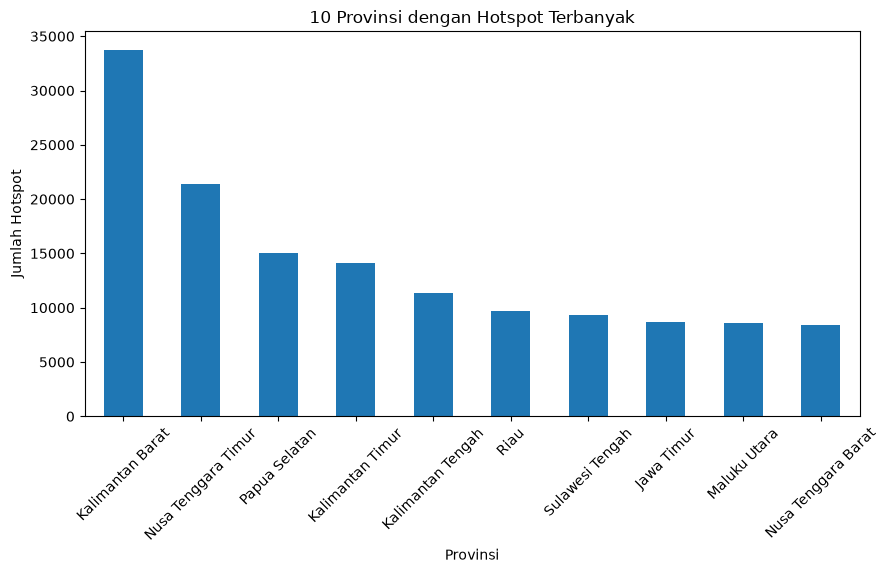

In [13]:
# Fungsi yang menampilkan 10 provinsi dengan jumlah hotspot terbanyak
top_provinsi = (
    df_combined["Provinsi"]
    .value_counts()
    .head(10)
)

# Visualisasi 10 provinsi dengan jumlah hotspot terbanyak menggunakan diagram batang dari library matplotlib
top_provinsi.plot(kind="bar", figsize=(10,5))
plt.title("10 Provinsi dengan Hotspot Terbanyak")
plt.xlabel("Provinsi")
plt.ylabel("Jumlah Hotspot")
plt.xticks(rotation=45)
plt.show()

Hasil: Kalimantan Barat memiliki titik hotspot terbanyak dengan jumlah mendekati 35 ribu dan disusul oleh Nusa Tenggara Timur dan yang lainnya.

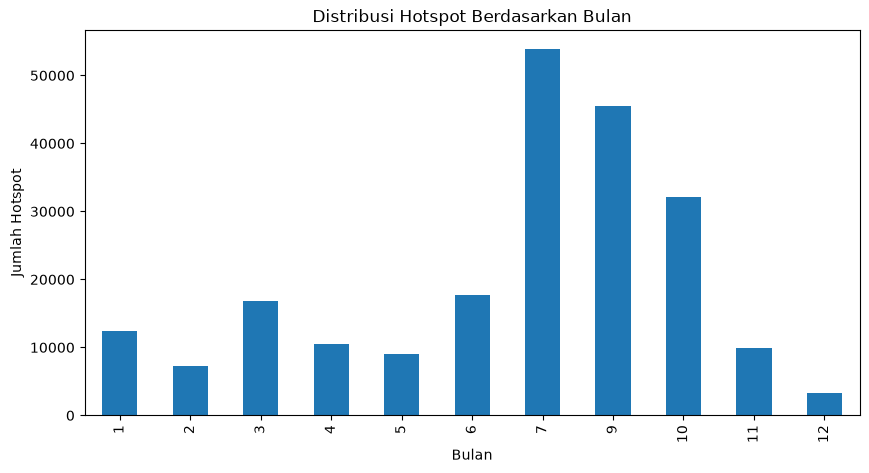

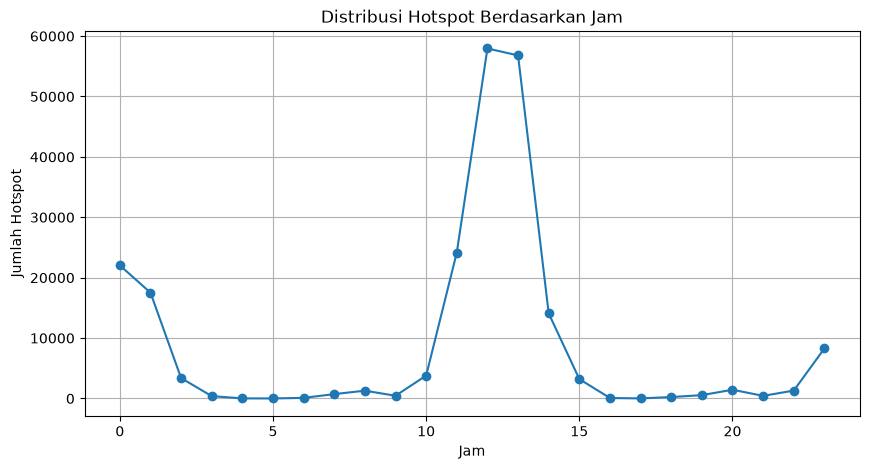

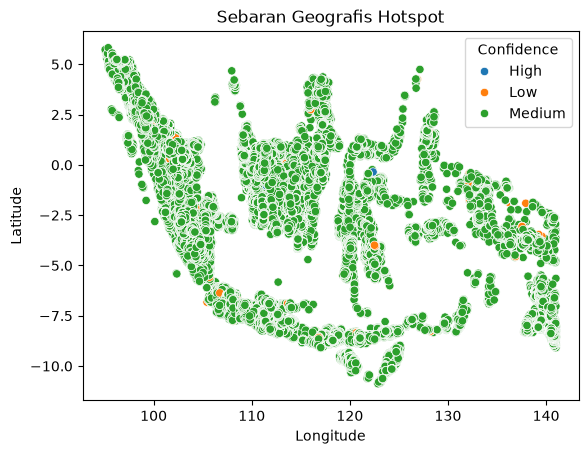

In [20]:
## Preprocessing Data
df_combined["Tanggal"] = pd.to_datetime(
    df_combined["Tanggal"],
    format="%d-%m-%Y"
)

# Menambahkan kolom "Bulan" dan "Jam" untuk analisis lebih lanjut
df_combined["Bulan"] = df_combined["Tanggal"].dt.month

# Menambahkan kolom "Jam" dengan menghapus " WIB" dari kolom "Waktu" dan mengonversi kolom menjadi format waktu, lalu mengambil jamnya saja
df_combined["Jam"] = pd.to_datetime(
    df_combined["Waktu"].str.replace(" WIB", ""),
    format="%H:%M"
).dt.hour

# Visualisasi Distribusi Hotspot Berdasarkan Bulan
df_combined["Bulan"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(10,5)
)
plt.title("Distribusi Hotspot Berdasarkan Bulan")
plt.xlabel("Bulan")
plt.ylabel("Jumlah Hotspot")
plt.show()

# Visualisasi Distribusi Hotspot Berdasarkan Jam
df_combined["Jam"].value_counts().sort_index().plot(
    kind="line",
    marker="o",
    figsize=(10,5)
)
plt.title("Distribusi Hotspot Berdasarkan Jam")
plt.xlabel("Jam")
plt.ylabel("Jumlah Hotspot")
plt.grid()
plt.show()

# Visualisasi Sebaran Geografis Hotspot
sns.scatterplot(
    data=df_combined,
    x="Longitude",
    y="Latitude",
    hue="Confidence"
)

plt.title("Sebaran Geografis Hotspot")
plt.show()

Hasil: Jika dikategorikan berdasarkan bulan, bulan 7 (Juli) menjadi bulan dengan deteksi hotspot paling banyak dibandingkan yang lainnya dan bulan 12 menjadi bulan dengan deteksi hotspot paling sedikit. Namun ketika dikategorikan berdasarkan jam, hotspot terdeteksi mengalami lonjakan yang dimulai pada jam 10 pagi (10) dan berakhir di jam 3 sore (15). Dan pada sebaran geografis, hotspot terdeteksi banyak ditrigger pada confidence medium di seluruh Indonesia.

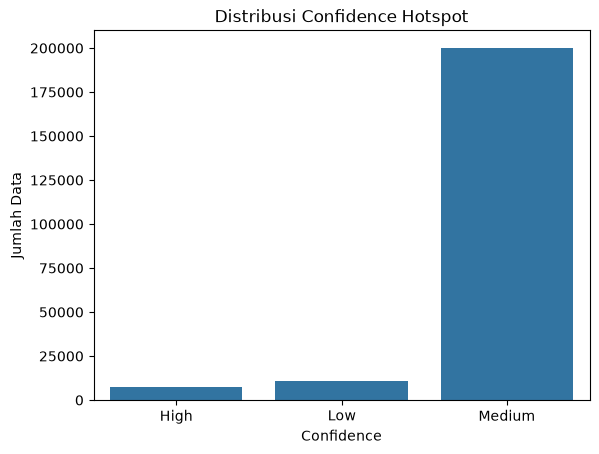

In [19]:
# Visualisasi Distribusi Confidence Hotspot
sns.countplot(data=df_combined, x="Confidence")

plt.title("Distribusi Confidence Hotspot")
plt.xlabel("Confidence")
plt.ylabel("Jumlah Data")
plt.show()


Hasil: Distribusi Confidence membuktikan jumlah deteksi hotspot mayoritas berada di level Medium.

### Soal 3. Data Cleaning
- Periksa missing values, duplikasi, inkonsistensi, dan nilai yang tidak masuk akal.
- Jelaskan bagaimana kalian mengatasi masalah di atas dan alasan penanganan setiap masalah dan dampaknya terhadap data.
- Bandingkan jumlah dan karakteristik data sebelum dan sesudah pembersihan.

Jawaban:
- Missing Value dan Duplikasi tidak ditemukan yang dapat mengganggu training model. Namun pada penulisan teks ada inkonsistensi pada spasi yang langsung diperbaiki.
- Pada masalah inkonsistensi, kami membersihkan data dengan cara menghapus spasi tambahan dan menormalkan kapitalisasi.
- Untuk jumlah tidak berubah dan untuk karakteristik data hanya diubah dengan menormalkan kapitalisasi di kolom yang terdeteksi inkonsistensinya.

In [22]:
# Check for Duplicates
print("Duplikat:", df_combined.duplicated().sum())

df_combined = df_combined.drop_duplicates()

# Check for missing values
print("Missing values:\n", df_combined.isnull().sum())

Duplikat: 0
Missing values:
 Provinsi       0
Kab Kota       2
Kecamatan     43
Desa           0
Tanggal        0
Waktu          0
Satelit        0
Confidence     0
Latitude       0
Longitude      0
Bulan          0
Jam            0
dtype: int64


Hasil: Adapun missing value yang ditemukan dikarenakan lokasi tersebut tidak memiliki lokasi spesifik (Kabupaten/Kota dan Kecamatan). Oleh karena itu, kami memilih untuk tidak mengambil penanganan apapun karena tetap bisa digunakan jika berdasarkan atribut lain.

In [37]:
kolom_kategori = [
    "Provinsi",
    "Kab Kota",
    "Kecamatan",
    "Desa",
    "Satelit",
    "Confidence"
]

for col in kolom_kategori:
    mask = (
        df_combined[col].notna() &
        df_combined[col].astype(str).ne(
            df_combined[col].astype(str).str.strip()
        )
    )

    print(f"{col}: {mask.sum()} inkonsistensi")



Provinsi: 0 inkonsistensi
Kab Kota: 0 inkonsistensi
Kecamatan: 0 inkonsistensi
Desa: 0 inkonsistensi
Satelit: 0 inkonsistensi
Confidence: 0 inkonsistensi


In [34]:
# Membersihkan data yang terdeteksi tidak konsisten sebelumnya
kolom_wilayah = ["Kecamatan", "Desa"]

# Membersihkan data dengan menghapus spasi tambahan dan menormalkan kapitalisasi
for kolom in kolom_wilayah:
    df_combined[kolom] = (
        df_combined[kolom]
        .astype("string")
        .str.strip()
        .str.title()
    )

Hasil: Mengatur kembali inkonsistensi yang terjadi dalam penulisan teks.

In [39]:
# Penyeragaman format teks pada kolom-kolom yang bersifat kategorikal
kolom_teks = [
    "Provinsi",
    "Kab Kota",
    "Kecamatan",
    "Desa",
    "Satelit",
    "Confidence"
]

# Membersihkan data dengan menghapus spasi tambahan dan menormalkan kapitalisasi
for col in kolom_teks:
    df_combined[col] = df_combined[col].astype("string").str.strip()

df_combined["Confidence"] = df_combined["Confidence"].str.title()

### Soal 4. Data Transformation
- Jelaskan apakah scaling atau encoding atribut kategorikal diperlukan, berikut alasannya.
- Tunjukkan data sebelum dan sesudah data transformation. 

Jawaban:
- Untuk scaling tidak perlu dilakukan untuk Decision Tree dan Random Forest yang akan diterapkan. Tetapi, encoding diperlukan untuk kategori yang digunakan.

In [54]:
# Mengubah tanggal menjadi format datetime
df_combined["Tanggal"] = pd.to_datetime(
    df_combined["Tanggal"],
    format="%d-%m-%Y"
)

# Mengubah waktu menjadi format jam
df_combined["Waktu"] = pd.to_datetime(
    df_combined["Waktu"],
    format="%H:%M WIB"
)
df_combined["Jam"] = df_combined["Waktu"].dt.hour
df_combined["Menit"] = df_combined["Waktu"].dt.minute

# Mengubah confidence menjadi skor numerik menggunakan mapping
df_combined["Waktu"] = pd.to_datetime(
    df_combined["Waktu"],
    format="%H:%M WIB"
)
df_combined["Jam"] = df_combined["Waktu"].dt.hour
df_combined["Menit"] = df_combined["Waktu"].dt.minute

# Mengubah data menjadi agregasi kecamatan per hari
daily_df = df_combined.groupby(
    ["Provinsi", "Kab Kota", "Kecamatan", "Tanggal"]
).agg(
    Hotspot_Count=("Latitude", "count"),
    High_Confidence_Count=(
        "Confidence",
        lambda x: (x == "High").sum()
    ),
    Avg_Latitude=("Latitude", "mean"),
    Avg_Longitude=("Longitude", "mean"),
    Avg_Confidence=("Confidence_Score", "mean")
).reset_index()
display(daily_df.head())

# Membuat panel tanggal lengkap
location_cols = [
    "Provinsi", "Kab Kota", "Kecamatan"
]

locations = daily_df[location_cols].drop_duplicates()

dates = pd.date_range(
    start=daily_df["Tanggal"].min(),
    end=daily_df["Tanggal"].max(),
    freq="D"
)

date_df = pd.DataFrame({"Tanggal": dates})

panel = locations.merge(date_df, how="cross")

daily_df = panel.merge(
    daily_df,
    on=location_cols + ["Tanggal"],
    how="left"
)

daily_df["Hotspot_Count"] = (
    daily_df["Hotspot_Count"].fillna(0)
)

daily_df["High_Confidence_Count"] = (
    daily_df["High_Confidence_Count"].fillna(0)
)

,Provinsi,Kab Kota,Kecamatan,Tanggal,Hotspot_Count,High_Confidence_Count,Avg_Latitude,Avg_Longitude,Avg_Confidence
0,Aceh,ACEH BARAT,Arongan Lambalek,2025-09-17,2,0,4.285275,96.019360,2.000000
1,Aceh,ACEH BARAT,Arongan Lambalek,2025-09-19,2,1,4.287370,96.017330,2.500000
2,Aceh,ACEH BARAT,Arongan Lambalek,2025-09-20,6,1,4.282870,96.021098,2.000000
3,Aceh,ACEH BARAT,Arongan Lambalek,2025-09-21,16,2,4.282848,96.017192,2.125000
4,Aceh,ACEH BARAT,Arongan Lambalek,2025-09-22,13,2,4.283843,96.017563,2.153846


In [56]:
### Feature Engineering
# Fitur kalender
daily_df["Month"] = daily_df["Tanggal"].dt.month

daily_df["Day"] = daily_df["Tanggal"].dt.day

daily_df["Day_of_Week"] = (
    daily_df["Tanggal"].dt.dayofweek
)

daily_df["Is_Weekend"] = (
    daily_df["Day_of_Week"] >= 5
).astype(int)

# Fitur historis hotspot
daily_df = daily_df.sort_values(
    ["Kecamatan", "Tanggal"]
)

daily_df["Hotspot_Lag_1"] = (
    daily_df.groupby("Kecamatan")["Hotspot_Count"]
    .shift(1)
)

daily_df["Hotspot_Lag_3"] = (
    daily_df.groupby("Kecamatan")["Hotspot_Count"]
    .transform(lambda x: x.shift(1).rolling(3).sum())
)

daily_df["Hotspot_Rolling_7"] = (
    daily_df.groupby("Kecamatan")["Hotspot_Count"]
    .transform(lambda x: x.shift(1).rolling(7).mean())
)

# Fitur rasio confidence
daily_df["High_Confidence_Ratio"] = np.where(
    daily_df["Hotspot_Count"] > 0,
    daily_df["High_Confidence_Count"] /
    daily_df["Hotspot_Count"],
    0
)

# Fitur untuk membuat target klasifikasi Risk Level
def classify_risk(count):
    if count == 0:
        return "Low"
    elif count <= 2:
        return "Medium"
    else:
        return "High"

daily_df["Risk_Level"] = (
    daily_df["Hotspot_Count"].apply(classify_risk)
)

# Fitur untuk menghapus baris yang tidak memiliki fitur historis
daily_df = daily_df.dropna(
    subset=[
        "Hotspot_Lag_1",
        "Hotspot_Lag_3",
        "Hotspot_Rolling_7"
    ]
)

display(daily_df.head())

C:\Users\maint\AppData\Local\Temp\ipykernel_23568\3983808607.py:8: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  daily_df["Tanggal"].dt.dayofweek


,Provinsi,Kab Kota,Kecamatan,Tanggal,Hotspot_Count,High_Confidence_Count,Avg_Latitude,Avg_Longitude,Avg_Confidence,Month,Day,Day_of_Week,Is_Weekend,Hotspot_Lag_1,Hotspot_Lag_3,Hotspot_Rolling_7,High_Confidence_Ratio,Risk_Level
807619,Lampung,LAMPUNG TIMUR,0,2025-09-08,4.0,0.0,-4.949642,105.68333,2.0,9,8,0,0,1.0,1.0,0.285714,0.0,High
807620,Lampung,LAMPUNG TIMUR,0,2025-09-09,0.0,0.0,NaN,NaN,NaN,9,9,1,0,4.0,5.0,0.714286,0.0,Low
807621,Lampung,LAMPUNG TIMUR,0,2025-09-10,0.0,0.0,NaN,NaN,NaN,9,10,2,0,0.0,5.0,0.714286,0.0,Low
807622,Lampung,LAMPUNG TIMUR,0,2025-09-11,0.0,0.0,NaN,NaN,NaN,9,11,3,0,0.0,4.0,0.714286,0.0,Low
807623,Lampung,LAMPUNG TIMUR,0,2025-09-12,0.0,0.0,NaN,NaN,NaN,9,12,4,0,0.0,0.0,0.714286,0.0,Low


### Soal 5. Pemodelan Regresi/Klasifikasi
- Gunakan minimal **dua algoritma regresi/klasifikasi** untuk dibandingkan (contoh: Linear Regression, Decision Tree Regressor, Random Forest Regressor atau KNN, Naive Bayes, Random Forest Classifier).
- Evaluasi model-model yang dihasilkan misalnya dengan **RMSE dan R-squared untuk regresi** atau **confusion matrix, accuracy, precision, recall, dan F1-score untuk klasifikasi** pada data uji.
- Bandingkan mana model terbaik berdasarkan hasil evaluasi.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Penentuan variabel target
y = daily_df["Risk_Level"]

# Penentuan variabel fitur
X = daily_df[
    [
        "Provinsi",
        "Kab Kota",
        "Kecamatan",
        "Month",
        "Day",
        "Day_of_Week",
        "Is_Weekend",
        "Hotspot_Lag_1",
        "Hotspot_Lag_3",
        "Hotspot_Rolling_7",
        "High_Confidence_Ratio"
    ]
]

# Pembagian dataset menjadi data latih dan data uji berdasarkan tanggal
daily_df = daily_df.sort_values("Tanggal")

split_date = daily_df["Tanggal"].quantile(0.8)

train_mask = daily_df["Tanggal"] <= split_date
test_mask = daily_df["Tanggal"] > split_date

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Encoding data kategorikal menggunakan OneHotEncoder dan melewatkan data numerik tanpa perubahan
categorical_features = [
    "Provinsi",
    "Kab Kota",
    "Kecamatan"
]

numeric_features = [
    "Month",
    "Day",
    "Day_of_Week",
    "Is_Weekend",
    "Hotspot_Lag_1",
    "Hotspot_Lag_3",
    "Hotspot_Rolling_7",
    "High_Confidence_Ratio"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "num",
            "passthrough",
            numeric_features
        )
    ]
)

Training: (1309485, 11)
Testing: (324610, 11)


In [68]:
# Implementasi model Decision Tree Classifier dengan pipeline
from sklearn.tree import DecisionTreeClassifier

dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42,
        class_weight="balanced"
    ))
])

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

In [67]:
# Implementasi model Random Forest Classifier dengan pipeline
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

In [72]:
# Cek Evaluasi Model dan Perbandingan Hasil
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

def evaluate_model(y_true, y_pred, model_name):

    print(f"\n===== {model_name} =====")

    print("Accuracy:",
        accuracy_score(y_true, y_pred))

    print("Precision:",
        precision_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ))

    print("Recall:",
        recall_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ))

    print("F1 Score:",
        f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ))

    print("\nClassification Report:")
    print(classification_report(
        y_true, y_pred,
        zero_division=0
    ))

evaluate_model(y_test, dt_pred, "Decision Tree")
evaluate_model(y_test, rf_pred, "Random Forest")

results = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(
            y_test, dt_pred,
            average="macro",
            zero_division=0
        ),
        precision_score(
            y_test, rf_pred,
            average="macro",
            zero_division=0
        )
    ],
    "Recall": [
        recall_score(
            y_test, dt_pred,
            average="macro",
            zero_division=0
        ),
        recall_score(
            y_test, rf_pred,
            average="macro",
            zero_division=0
        )
    ],
    "F1-Score": [
        f1_score(
            y_test, dt_pred,
            average="macro",
            zero_division=0
        ),
        f1_score(
            y_test, rf_pred,
            average="macro",
            zero_division=0
        )
    ]
})

display(results)


===== Decision Tree =====
Accuracy: 0.7722559378947044
Precision: 0.4609330893740122
Recall: 0.6186524000676795
F1 Score: 0.48505683496225266

Classification Report:
              precision    recall  f1-score   support

        High       0.30      0.62      0.40      6934
         Low       0.97      0.79      0.87    301583
      Medium       0.11      0.44      0.18     16093

    accuracy                           0.77    324610
   macro avg       0.46      0.62      0.49    324610
weighted avg       0.92      0.77      0.83    324610


===== Random Forest =====
Accuracy: 0.8060287729891255
Precision: 0.40538259286737444
Recall: 0.5870078668158502
F1 Score: 0.4240125465625033

Classification Report:
              precision    recall  f1-score   support

        High       0.15      0.75      0.24      6934
         Low       0.97      0.84      0.90    301583
      Medium       0.10      0.17      0.13     16093

    accuracy                           0.81    324610
   macro avg 

,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.772256,0.460933,0.618652,0.485057
1,Random Forest,0.806029,0.405383,0.587008,0.424013


Accuracy    = Persentase prediksi yang benar | Random Forest memiliki persentase prediksi yang lebih baik.

Precision   = Ketepatan prediksi pada suatu kelas | Decision Tree memiliki ketepatan yang lebih baik.

Recall      = Kemampuan menemukan seluruh data dari suatu kelas | Secara angka, Decision Tree lebih baik.

F1-Score	= Keseimbangan precision dan recall | F1-Score menunjukkan Decision Tree memiliki keseimbangan yang lebih baik.

Secara head to head, Decision Tree memiliki prediksi yang lebih baik dibandingkan Random Forest namun Random Forest memiliki tingkat persentase prediksi yang benar yang lebih tinggi.

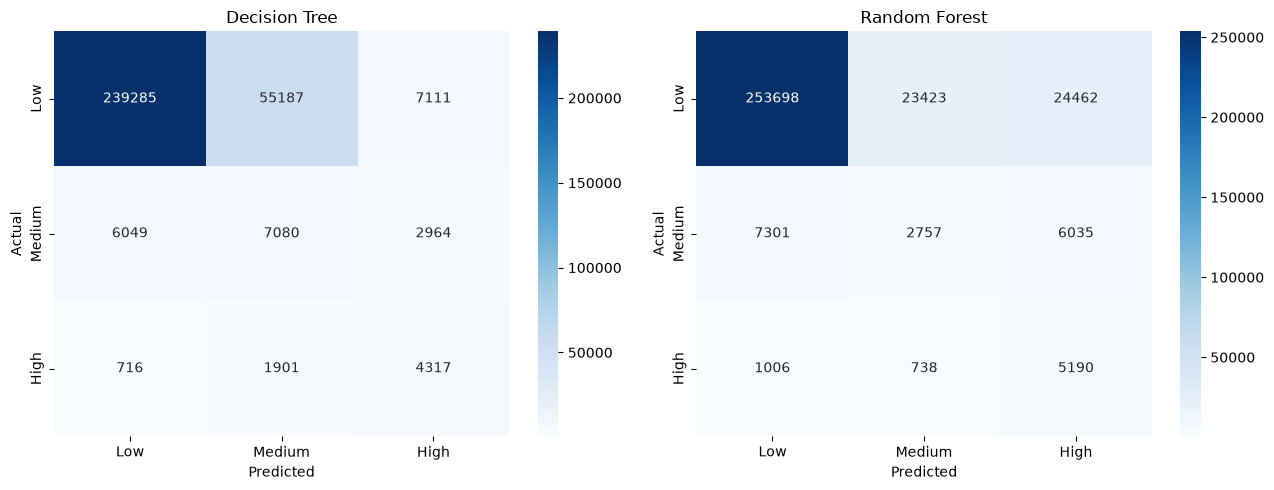

In [73]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, pred, title in [
    (axes[0], dt_pred, "Decision Tree"),
    (axes[1], rf_pred, "Random Forest")
]:

    cm = confusion_matrix(
        y_test,
        pred,
        labels=["Low", "Medium", "High"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Low", "Medium", "High"],
        yticklabels=["Low", "Medium", "High"],
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

Berdasarkan hasil evaluasi menggunakan Confusion Matrix, algoritma Decision Tree memperoleh accuracy sebesar 77,23%, sedangkan Random Forest memperoleh accuracy sebesar 80,60%. Berdasarkan metrik accuracy, Random Forest menunjukkan performa yang lebih tinggi dibandingkan Decision Tree.

Namun, berdasarkan evaluasi Macro F1-Score, Decision Tree memperoleh nilai 48,51%, lebih tinggi dibandingkan Random Forest sebesar 42,40%. Hal ini menunjukkan bahwa Decision Tree memiliki kemampuan klasifikasi yang relatif lebih seimbang dalam mengenali ketiga kategori risiko, yaitu Low, Medium, dan High.

Pada kategori High Risk, Random Forest memiliki recall sebesar 74,85%, sedangkan Decision Tree sebesar 62,26%. Hal tersebut menunjukkan bahwa Random Forest lebih mampu mendeteksi sampel yang benar-benar termasuk dalam kategori risiko tinggi. Namun, precision Random Forest pada kategori High hanya sebesar 14,54%, lebih rendah dibandingkan Decision Tree sebesar 30,00%.

Selain itu, ditemukan ketidakseimbangan distribusi kelas pada dataset, dengan kategori Low mendominasi sebesar 92,91%, sedangkan kategori Medium dan High masing-masing hanya sebesar 4,96% dan 2,14%. Kondisi ini berpotensi menyebabkan model lebih berorientasi pada klasifikasi kategori Low dibandingkan kategori lainnya.

Dengan demikian, Decision Tree dapat dianggap lebih baik berdasarkan keseimbangan performa antarkelas, sedangkan Random Forest memiliki kemampuan lebih tinggi dalam menemukan kejadian High Risk. Penanganan class imbalance dan optimasi hyperparameter masih diperlukan untuk meningkatkan kualitas klasifikasi, khususnya pada kategori Medium dan High.

### Soal 6. Interpretasi dan insight yang ditemukan dari hasil penambangan data.
- Buat **minimal 3 temuan penting** yang diturunkan dari hasil analisis dan jelaskan bukti pendukungnya.

,Feature,Importance
5383,num__Hotspot_Rolling_7,0.136782
5381,num__Hotspot_Lag_1,0.130519
5382,num__Hotspot_Lag_3,0.117014
5384,num__High_Confidence_Ratio,0.070115
5377,num__Month,0.046051
12,cat__Provinsi_Kalimantan Barat,0.022971
23,cat__Provinsi_Nusa Tenggara Timur,0.021570
5259,cat__Kecamatan_Weda Tengah,0.020085
11,cat__Provinsi_Jawa Timur,0.017474
10,cat__Provinsi_Jawa Tengah,0.017095


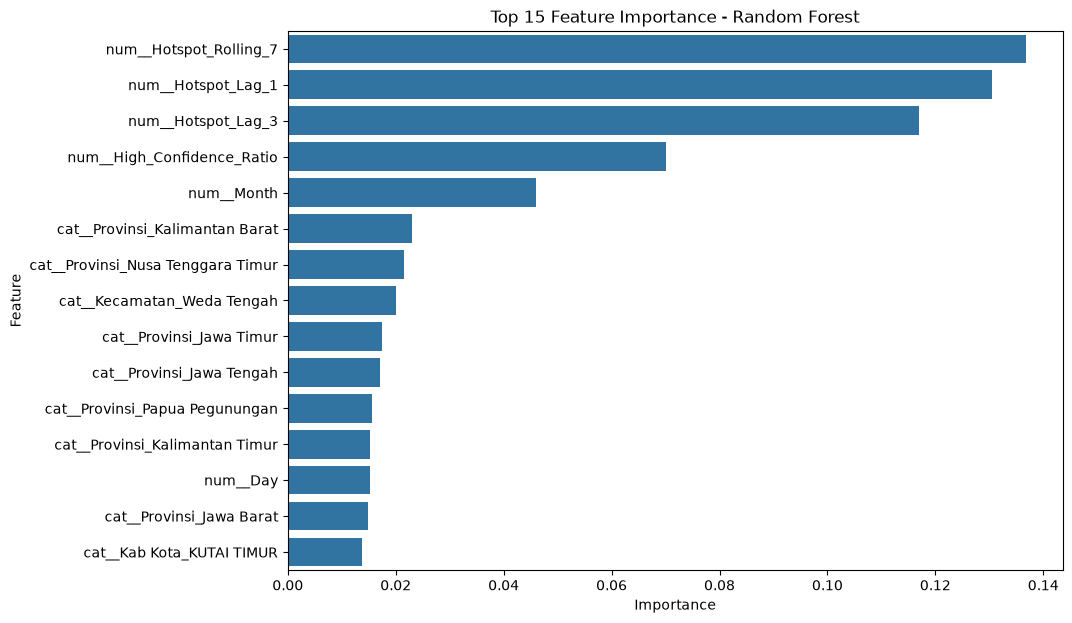

In [75]:
# Mengambil preprocessing dan model Random Forest
preprocessor_fitted = rf_model.named_steps["preprocessor"]

classifier = rf_model.named_steps["classifier"]

# Mengambil nama fitur setelah encoding
feature_names = (
    preprocessor_fitted.get_feature_names_out()
)

# Mengambil feature importance
importance = classifier.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(15))

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

Hasil: Arti intepretasi dari Feature Importance di atas, ketiga fitur paling atas memiliki importance sebesar 0.384315 atau sekitar 38,43% dari total importance model. Artinya, ketiga fitur historis tersebut memiliki kontribusi relatif yang cukup besar terhadap proses klasifikasi.

Insight:
Aktivitas hotspot pada periode sebelumnya menjadi informasi penting bagi Random Forest dalam membedakan kategori intensitas hotspot. Hal ini mengindikasikan adanya pola temporal, yaitu kejadian hotspot pada suatu wilayah memiliki keterkaitan prediktif dengan aktivitas hotspot pada periode berikutnya.

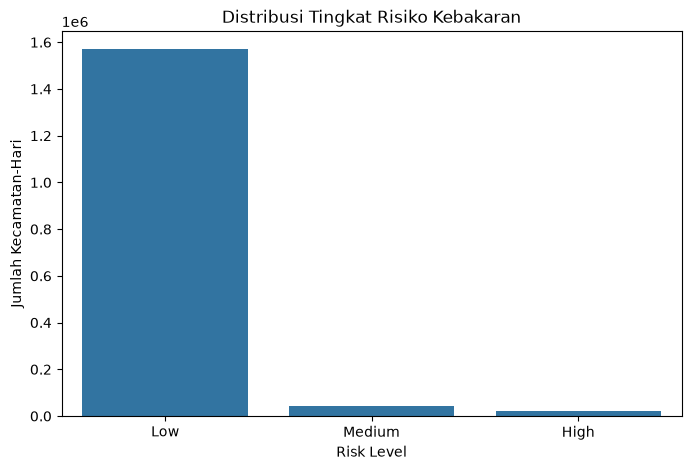

In [77]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=daily_df,
    x="Risk_Level",
    order=["Low", "Medium", "High"]
)

plt.title("Distribusi Tingkat Risiko Kebakaran")
plt.xlabel("Risk Level")
plt.ylabel("Jumlah Kecamatan-Hari")

plt.show()

Hasil: Mayoritas dataset memiliki resiko kebakaran yang rendah. Dapat dilihat dari hasil distribusi didominasi oleh risk level "Low". Ini dapat dianggap bahwa distribusi kelas tidak seimbang sehingga distribusi risk levelnya sangat terdominasi oleh level "Low".

Insight: Distribusi level bisa disesuaikan.

In [78]:
high_risk_area = daily_df[
    daily_df["Risk_Level"] == "High"
]

top_high_risk = (
    high_risk_area.groupby(
        ["Provinsi", "Kab Kota", "Kecamatan"]
    )
    .size()
    .reset_index(name="High_Risk_Days")
    .sort_values(
        "High_Risk_Days",
        ascending=False
    )
)

display(top_high_risk.head(10))

,Provinsi,Kab Kota,Kecamatan,High_Risk_Days
1187,Maluku Utara,HALMAHERA TENGAH,Weda Tengah,235
1184,Maluku Utara,HALMAHERA SELATAN,Obi,229
2066,Sulawesi Tenggara,KONAWE,Morosi,204
1879,Sulawesi Selatan,LUWU TIMUR,Towuti,196
965,Kalimantan Timur,PASER,Batu Sopang,186
942,Kalimantan Timur,KUTAI TIMUR,Bengalon,173
450,Jawa Timur,MALANG,Ampelgading,166
1975,Sulawesi Tengah,MOROWALI UTARA,Petasia,151
1964,Sulawesi Tengah,MOROWALI,Bahodopi,146
1180,Maluku Utara,HALMAHERA BARAT,Ibu,145


Hasil: Kecamatan Weda Tengah memiliki intensitas hotspot tertinggi dengan 235 High Risk Days dengan Kecamatan Obi yang sama-sama berada di Halmahera, Provinsi Maluku Utara memiliki intensitas 229 High Risk Days yang berarti cukup parah.

Insight: Perhatian lebih sepatutnya diberikan ke Provinsi Maluku Utara karena intensitas tersebut tidak bisa dianggap sepele. Dan di antara 10 teratas, 3 kecamatan di Maluku Utara masuk ke tabel yang menunjukkan intensitas yang tinggi.
Namun ketika dilihat secara pulau, pulau Sulawesi menjadi pulau yang paling banyak terlihat di tingkat 10 teratas tersebut.